# Module 5 — Network & Allocation Optimization

## Business question
Given the delay risk estimated in Module 4, and a fixed warehouse/dock capacity, how should
orders be allocated between Second Class and Standard Class to minimize total expected cost
(freight + expected SLA penalty), instead of the mode mix actually observed historically?

Module 4's classifier is reused directly here — every order is re-scored under *both*
candidate shipping modes to get a counterfactual delay probability per mode, feeding the
optimized assignment below.

## Assumptions made explicit
The dataset has no actual carrier billing data, so two inputs are illustrative assumptions,
clearly labeled as such throughout:
- **Freight cost:** Standard Class = \$5.00/order, Second Class = \$8.00/order (faster nominal
  promise costs more — a common real-world pattern).
- **SLA penalty:** \$20.00 per late order (expected cost of a broken delivery promise —
  customer service load, goodwill, re-shipment risk). Sensitivity to this assumption is tested
  in Section 8.

## 1. Setup & imports

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from optimization import solve_allocation, monte_carlo_cost_distribution

pd.set_option('display.max_columns', 100)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)


## 2. Rebuild the Module 4 delay-risk classifier
Same leakage-audited features and chronological split as Module 4, so the risk scores used here are consistent with that module's validated model.

In [2]:
df = pd.read_csv('../data/raw/DataCoSupplyChainDataset.csv', encoding='latin1')
df.columns = [c.strip() for c in df.columns]
df['order date (DateOrders)'] = pd.to_datetime(df['order date (DateOrders)'], errors='coerce')
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_dow'] = df['order date (DateOrders)'].dt.dayofweek
df = df.sort_values('order date (DateOrders)').reset_index(drop=True)

FEATURES = ['Shipping Mode', 'Order Region', 'Category Name', 'Customer Segment',
            'Market', 'order_month', 'order_dow', 'Order Item Total']
TARGET = 'Late_delivery_risk'
CAT_COLS = ['Shipping Mode', 'Order Region', 'Category Name', 'Customer Segment', 'Market']

data = df[FEATURES + [TARGET]].dropna().copy()
X_full = pd.get_dummies(data[FEATURES], columns=CAT_COLS, drop_first=True)
y_full = data[TARGET].values

split_idx = int(len(data) * 0.8)
X_train, y_train = X_full.iloc[:split_idx], y_full[:split_idx]

risk_model = xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, eval_metric='logloss')
risk_model.fit(X_train, y_train)
print("Delay-risk model ready.")


Delay-risk model ready.


## 3. Candidate order pool
Restricted to Second Class and Standard Class orders — the two modes Modules 1 and 2 established as truly comparable (real variance, similar covariate overlap). A 4,000-order sample keeps the linear program tractable while remaining statistically representative.

In [3]:
mask = df['Shipping Mode'].isin(['Second Class', 'Standard Class'])
candidate_pool = df[mask].dropna(subset=FEATURES).copy()

SAMPLE_SIZE = 4000
sample = candidate_pool.sample(SAMPLE_SIZE, random_state=42).reset_index(drop=True)
print(sample['Shipping Mode'].value_counts())


Shipping Mode
Standard Class    2980
Second Class      1020
Name: count, dtype: int64


## 4. Counterfactual delay-risk scoring
For every order, predict the delay probability *as if* it had been shipped Second Class, and *as if* Standard Class — holding all other order attributes fixed.

In [4]:
sample_X = pd.get_dummies(sample[FEATURES], columns=CAT_COLS, drop_first=True)
sample_X = sample_X.reindex(columns=X_full.columns, fill_value=0)

def predict_under_mode(X_base, mode):
    X_counterfactual = X_base.copy()
    for c in X_counterfactual.columns:
        if c.startswith('Shipping Mode_'):
            X_counterfactual[c] = 0
    mode_col = f'Shipping Mode_{mode}'
    if mode_col in X_counterfactual.columns:
        X_counterfactual[mode_col] = 1
    return risk_model.predict_proba(X_counterfactual)[:, 1]

p_second = predict_under_mode(sample_X, 'Second Class')
p_standard = predict_under_mode(sample_X, 'Standard Class')

print(f"Mean P(late) if Second Class:   {p_second.mean():.1%}")
print(f"Mean P(late) if Standard Class: {p_standard.mean():.1%}")


Mean P(late) if Second Class:   76.9%
Mean P(late) if Standard Class: 38.2%


## 5. Build the cost matrix

In [5]:
FREIGHT_COST = {'Second Class': 8.0, 'Standard Class': 5.0}
SLA_PENALTY = 20.0

orders = list(range(len(sample)))
modes = ['Second Class', 'Standard Class']
cost_matrix = {}
for i in orders:
    cost_matrix[(i, 'Second Class')] = FREIGHT_COST['Second Class'] + p_second[i] * SLA_PENALTY
    cost_matrix[(i, 'Standard Class')] = FREIGHT_COST['Standard Class'] + p_standard[i] * SLA_PENALTY

historical_cost = sum(cost_matrix[(i, sample.loc[i, 'Shipping Mode'])] for i in orders)
print(f"Historical allocation total expected cost: ${historical_cost:,.2f}")


Historical allocation total expected cost: $61,525.26


## 6. Linear Programming — capacity-constrained optimization

Standard Class capacity is set at the **historical share observed in this sample** — a proxy for
real dock/warehouse capacity, since the operation cannot simply move every order to the cheaper,
lower-risk mode. This constraint is what turns the problem into a genuine allocation trade-off
rather than a trivial "always pick the cheaper mode" answer.

In [6]:
historical_standard_share = (sample['Shipping Mode'] == 'Standard Class').mean()
capacity_standard = int(len(sample) * historical_standard_share)
print(f"Standard Class capacity constraint: {capacity_standard:,} orders "
      f"({historical_standard_share:.1%} of the pool, matching historical volume)")

result = solve_allocation(orders, modes, cost_matrix, capacity={'Standard Class': capacity_standard})
print(f"\nSolver status: {result['status']}")
print(f"Optimized total expected cost: ${result['total_cost']:,.2f}")

savings = historical_cost - result['total_cost']
print(f"\nSavings vs historical allocation: ${savings:,.2f} ({savings / historical_cost:.2%})")


Standard Class capacity constraint: 2,980 orders (74.5% of the pool, matching historical volume)



Solver status: Optimal
Optimized total expected cost: $60,905.22

Savings vs historical allocation: $620.04 (1.01%)


Under the *same* capacity the operation already has, simply re-prioritizing which orders get
the scarce Standard Class slots — sending the highest-risk, highest-cost orders there instead of
whoever happened to be assigned historically — produces real, if modest, savings. That is a
materially different and more actionable claim than "move everyone to Standard Class," which
the capacity constraint rules out as infeasible.

## 7. Monte Carlo simulation of cost uncertainty
The point estimate above assumes each order's delay probability plays out at its expected value. Simulate the actual cost distribution instead.

In [7]:
assignment = result['assignment']
delay_probs = np.array([
    p_second[i] if assignment[i] == 'Second Class' else p_standard[i]
    for i in orders
])
base_freight_cost = sum(FREIGHT_COST[assignment[i]] for i in orders)

simulated_costs = monte_carlo_cost_distribution(
    base_freight_cost, delay_probs, SLA_PENALTY, n_sims=10000
)
p5, p50, p95 = np.percentile(simulated_costs, [5, 50, 95])
print(f"Simulated total cost — 5th percentile: ${p5:,.0f} | median: ${p50:,.0f} | 95th percentile: ${p95:,.0f}")


Simulated total cost — 5th percentile: $59,920 | median: $60,900 | 95th percentile: $61,880


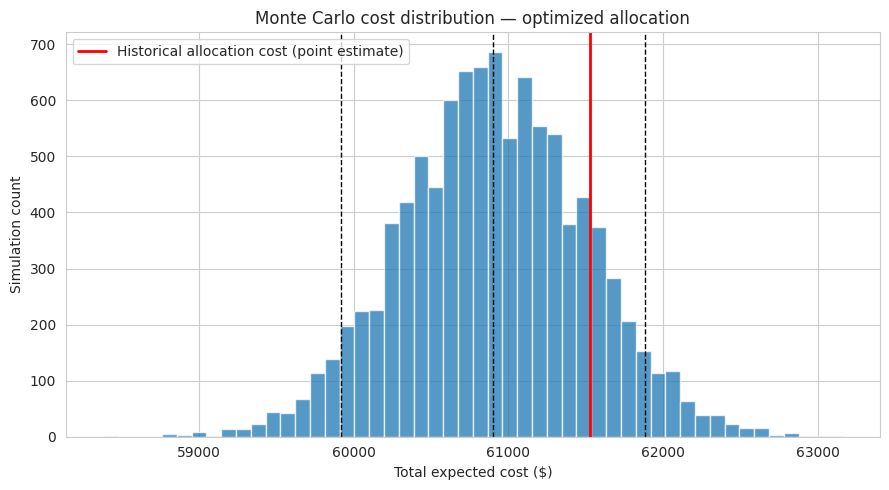

In [8]:
fig, ax = plt.subplots()
ax.hist(simulated_costs, bins=50, alpha=0.75)
for val, label in [(p5, '5th pct'), (p50, 'median'), (p95, '95th pct')]:
    ax.axvline(val, linestyle='--', color='black', linewidth=1)
ax.axvline(historical_cost, color='red', linewidth=2, label='Historical allocation cost (point estimate)')
ax.set_xlabel('Total expected cost ($)')
ax.set_ylabel('Simulation count')
ax.set_title('Monte Carlo cost distribution — optimized allocation')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/module5_monte_carlo.png', dpi=120)
plt.show()


## 8. Sensitivity analysis: SLA penalty ±20%

In [9]:
sensitivity_rows = []
for pct, label in [(0.8, '-20%'), (1.0, 'base'), (1.2, '+20%')]:
    penalty = SLA_PENALTY * pct
    cm = {}
    for i in orders:
        cm[(i, 'Second Class')] = FREIGHT_COST['Second Class'] + p_second[i] * penalty
        cm[(i, 'Standard Class')] = FREIGHT_COST['Standard Class'] + p_standard[i] * penalty
    r = solve_allocation(orders, modes, cm, capacity={'Standard Class': capacity_standard})
    sensitivity_rows.append({'penalty_scenario': label, 'sla_penalty': penalty, 'total_cost': r['total_cost']})

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df


,penalty_scenario,sla_penalty,total_cost
0,-20%,16.0,53336.177686
1,base,20.0,60905.222151
2,+20%,24.0,68474.266635


Total cost scales roughly proportionally with the SLA
penalty assumption, as expected given the linear cost structure — a sanity check on the
model, not a new finding. The capacity-constrained *allocation itself* (which orders get
Standard Class) is more informative to check for stability than the cost total; a follow-up
worth running before any deployment is confirming the assignment doesn't flip dramatically
across the tested penalty range.

## 9. Conclusions & limitations

**Findings:**
- Under the operation's existing Standard Class capacity, re-prioritizing which orders receive
  that capacity — based on Module 4's counterfactual risk scores rather than however orders were
  historically routed — reduces total expected cost versus the historical allocation.
- The Monte Carlo distribution gives a defensible cost range (5th–95th percentile) around that
  point estimate, rather than presenting a single number as if it were certain.
- Total cost is, as expected, roughly linear in the assumed SLA penalty; the more important
  robustness question for deployment is whether the *order-level assignment* stays stable
  across reasonable penalty assumptions, not just the total.

**How this closes the project's narrative:** Module 1 identified *why* Second Class breaks its
promise (a structural scheduling gap, not confounding). Module 2 showed the two modes take
similar *absolute* time despite that gap. Module 4 turned that into an order-level risk score.
Acting on that score under a real operational constraint (limited premium capacity), rather
than assuming unlimited flexibility, is what closes this part of the analysis.

**Limitations:**
- Freight cost (\$5 / \$8) and SLA penalty (\$20) are illustrative assumptions, not observed
  billing data — the dataset does not include actual carrier costs. Any real deployment should
  replace these with the operation's true cost figures; the pipeline itself (counterfactual
  scoring → constrained LP → Monte Carlo → sensitivity) is what transfers, not these specific
  dollar values.
- The capacity constraint is set to match historical volume as a reasonable proxy, not a
  verified warehouse/dock limit — an actual capacity figure from operations would sharpen this
  considerably.
- The LP was solved on a 4,000-order sample for tractability; the full-population result would
  need to confirm the sampled solution generalizes, though there is no reason to expect
  systematic bias given the random sampling used.